# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   str    
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 106.6 KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: <StringArray>
['Asia', 'Europe', 'Africa', 'Americas', 'Oceania']
Length: 5, dtype: str
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


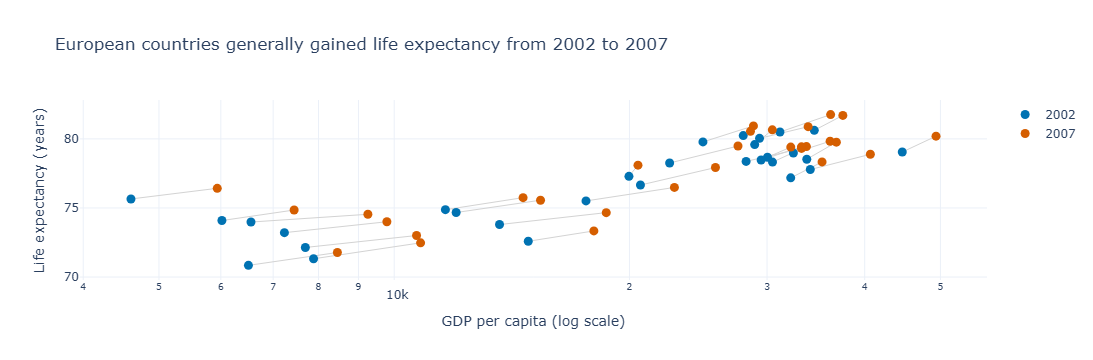

In [3]:
# Task 1: GDP per capita vs life expectancy, Europe

import plotly.graph_objects as go

continent = "Europe"
years = [2002, 2007]

subset = df[
    (df["continent"] == continent) &
    (df["year"].isin(years))
]

fig = go.Figure()

# Connect each country's 2002 and 2007 points
for country, group in subset.groupby("country"):
    group = group.sort_values("year")

    fig.add_trace(go.Scatter(
        x=group["gdpPercap"],
        y=group["lifeExp"],
        mode="lines",
        line=dict(color="lightgrey", width=1),
        hoverinfo="skip",
        showlegend=False
    ))

# Show the two years using just two colours
for year, colour in [(2002, "#0072B2"), (2007, "#D55E00")]:
    data = subset[subset["year"] == year]

    fig.add_trace(go.Scatter(
        x=data["gdpPercap"],
        y=data["lifeExp"],
        mode="markers",
        name=str(year),
        marker=dict(color=colour, size=9),
        text=data["country"],
        hovertemplate=(
            "<b>%{text}</b><br>"
            "GDP per capita: %{x:,.0f}<br>"
            "Life expectancy: %{y:.1f} years"
            "<extra></extra>"
        )
    ))

fig.update_layout(
    title="European countries generally gained life expectancy from 2002 to 2007",
    xaxis_title="GDP per capita (log scale)",
    yaxis_title="Life expectancy (years)",
    template="plotly_white"
)

fig.update_xaxes(type="log")

fig.show()

## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


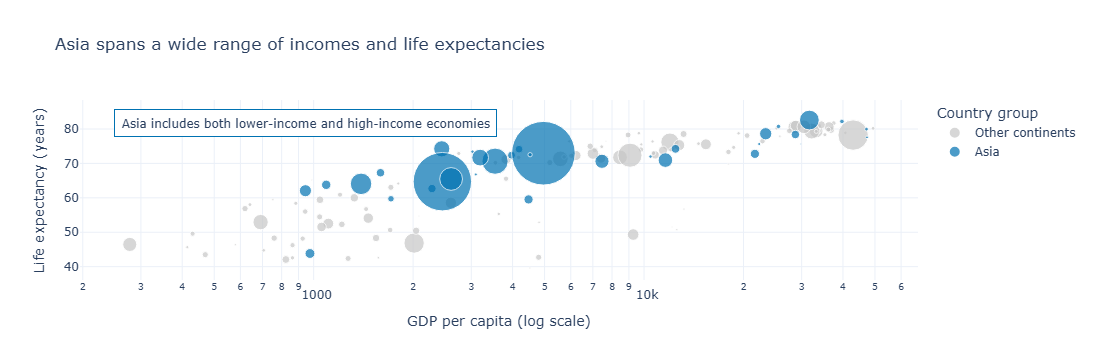

In [4]:
# Task 2: Gapminder bubble chart for 2007

year_data = df[df["year"] == 2007].copy()

highlight = "Asia"
year_data["group"] = year_data["continent"].apply(
    lambda x: highlight if x == highlight else "Other continents"
)

# Draw other continents first so the highlighted bubbles remain visible
fig = px.scatter(
    year_data.sort_values("group", ascending=False),
    x="gdpPercap",
    y="lifeExp",
    size="pop",
    color="group",
    color_discrete_map={
        "Other continents": "#C7C7C7",
        "Asia": "#0072B2"
    },
    size_max=45,
    hover_name="country",
    hover_data={
        "continent": True,
        "gdpPercap": ":,.0f",
        "lifeExp": ":.1f",
        "pop": ":,.0f",
        "group": False
    },
    log_x=True,
    title="Asia spans a wide range of incomes and life expectancies"
)

fig.update_layout(
    xaxis_title="GDP per capita (log scale)",
    yaxis_title="Life expectancy (years)",
    legend_title="Country group",
    template="plotly_white"
)

fig.add_annotation(
    x=0.04,
    y=0.95,
    xref="paper",
    yref="paper",
    text="Asia includes both lower-income and high-income economies",
    showarrow=False,
    align="left",
    bgcolor="white",
    bordercolor="#0072B2",
    borderwidth=1,
    borderpad=6
)

fig.show()